# 例4-12

(768, 1024)


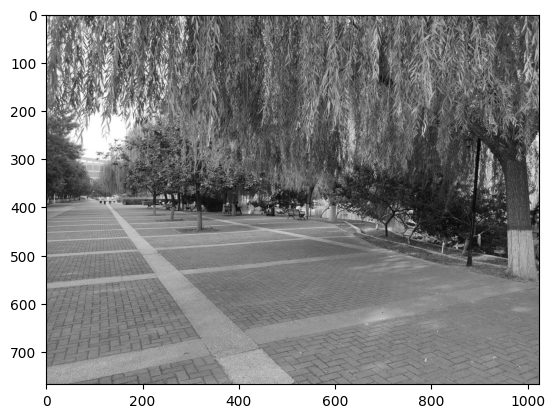

768 1024
uint8


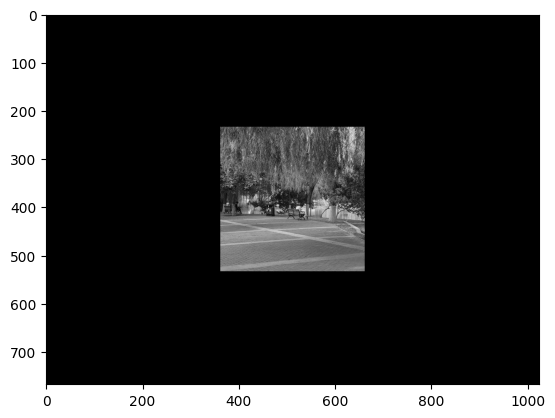

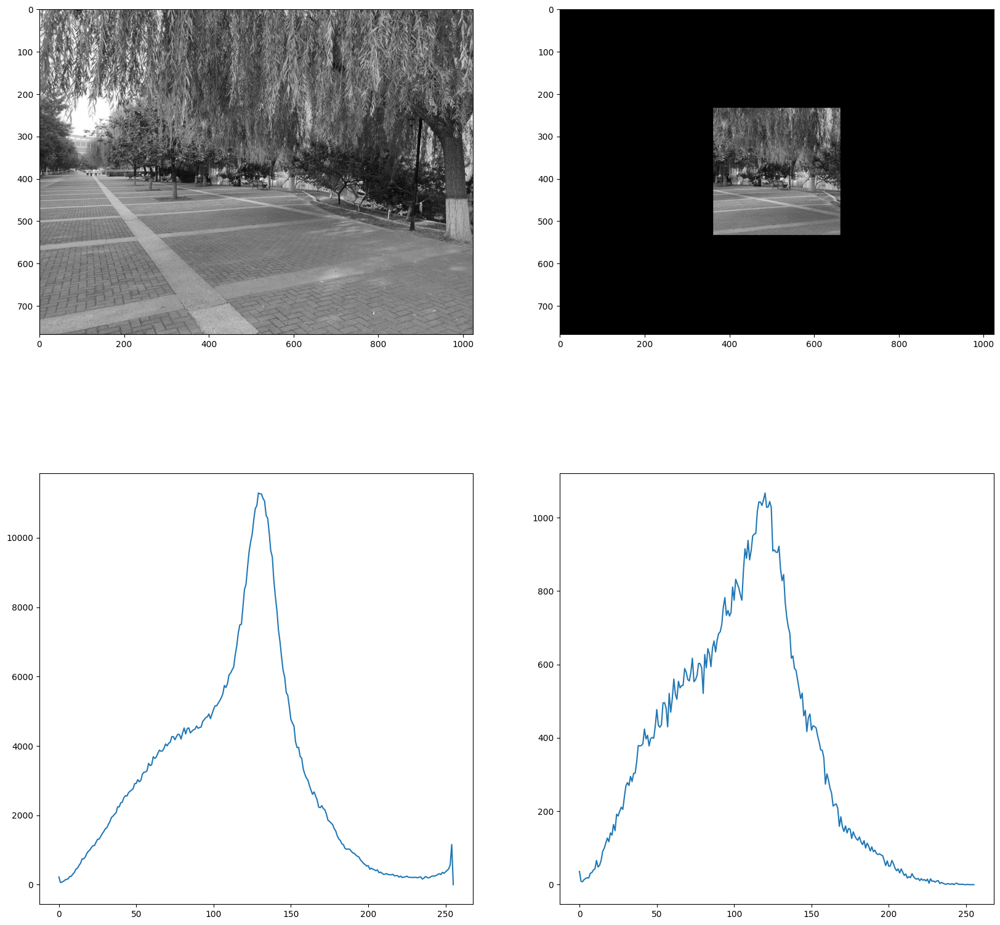

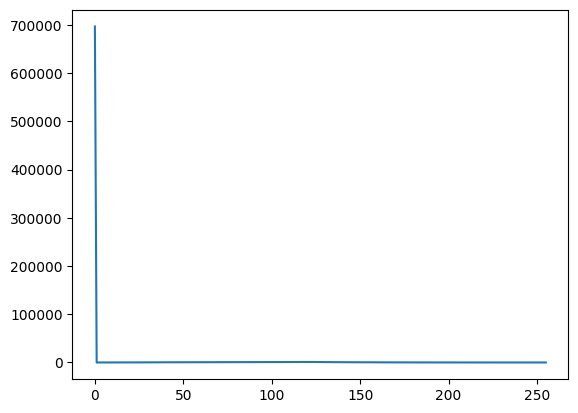

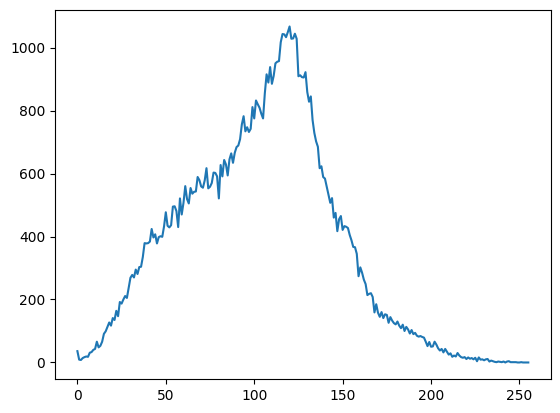

[[6.96468e+05]
 [9.00000e+00]
 [8.00000e+00]
 [1.40000e+01]
 [1.70000e+01]
 [1.90000e+01]
 [1.80000e+01]
 [3.10000e+01]
 [3.30000e+01]
 [4.00000e+01]
 [4.30000e+01]
 [6.60000e+01]
 [4.80000e+01]
 [5.30000e+01]
 [6.60000e+01]
 [9.10000e+01]
 [9.90000e+01]
 [1.13000e+02]
 [1.27000e+02]
 [1.17000e+02]
 [1.41000e+02]
 [1.35000e+02]
 [1.64000e+02]
 [1.47000e+02]
 [1.92000e+02]
 [1.87000e+02]
 [2.00000e+02]
 [2.11000e+02]
 [2.05000e+02]
 [2.38000e+02]
 [2.69000e+02]
 [2.78000e+02]
 [2.70000e+02]
 [2.95000e+02]
 [2.81000e+02]
 [3.03000e+02]
 [3.04000e+02]
 [3.35000e+02]
 [3.79000e+02]
 [3.78000e+02]
 [3.79000e+02]
 [3.84000e+02]
 [4.24000e+02]
 [3.97000e+02]
 [4.07000e+02]
 [3.78000e+02]
 [3.98000e+02]
 [4.01000e+02]
 [3.99000e+02]
 [4.32000e+02]
 [4.77000e+02]
 [4.34000e+02]
 [4.29000e+02]
 [4.36000e+02]
 [4.95000e+02]
 [4.96000e+02]
 [4.81000e+02]
 [4.30000e+02]
 [5.21000e+02]
 [4.70000e+02]
 [5.07000e+02]
 [5.60000e+02]
 [5.19000e+02]
 [5.05000e+02]
 [5.54000e+02]
 [5.36000e+02]
 [5.42000e

In [1]:
import numpy as np 
import matplotlib.pyplot as plt
import cv2 

path = '/home/aistudio/work/'
image_gray = cv2.imread(path + 'campus_1024_768_gray.jpg',0)
print(image_gray.shape)
plt.imshow(image_gray,'gray')
plt.show()

rows,cols = image_gray.shape
print(rows,cols)
centerX = int(rows/2)
centerY = int(cols/2)
height = 300
width = 300

mask_gray = np.zeros(image_gray.shape,np.uint8)
mask_gray[centerX-int(height/2):centerX+int(height/2),centerY-int(width/2):centerY+int(width/2)] = np.uint8(255)
roi = image_gray[centerX-int(height/2):centerX+int(height/2),centerY-int(width/2):centerY+int(width/2)]
image_masked =np.bitwise_and(image_gray,mask_gray)
print(mask_gray.dtype)
plt.imshow(image_masked,'gray')
plt.show()

hist_full = cv2.calcHist([image_gray],[0],None,[256],[0,255])
hist_mask =cv2.calcHist([image_gray],[0],mask_gray,[256],[0,255])

hist_image_masked = cv2.calcHist([image_masked],[0],None,[256],[0,255])
hist_image_roi = cv2.calcHist([roi],[0],None,[256],[0,255])
plt.figure(figsize=(20,20))
plt.subplot(2,2,1)
plt.imshow(image_gray,'gray')
plt.subplot(2,2,2)
plt.imshow(image_masked,'gray')
plt.subplot(2,2,3)
plt.plot(hist_full)

plt.subplot(2,2,4)
plt.plot(hist_mask)


plt.show()

plt.plot(hist_image_masked)
plt.show()
plt.plot(hist_image_roi)
plt.show()

print(hist_image_masked)




# 例4-14

(768, 1024)


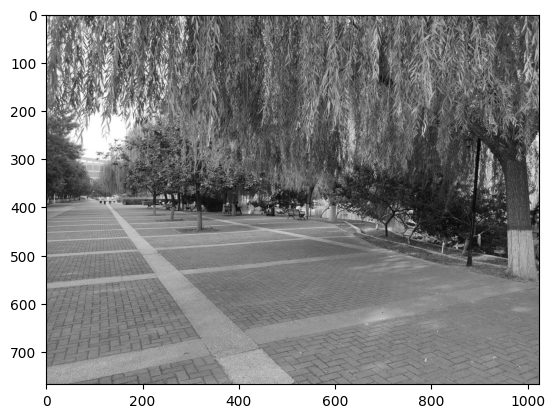

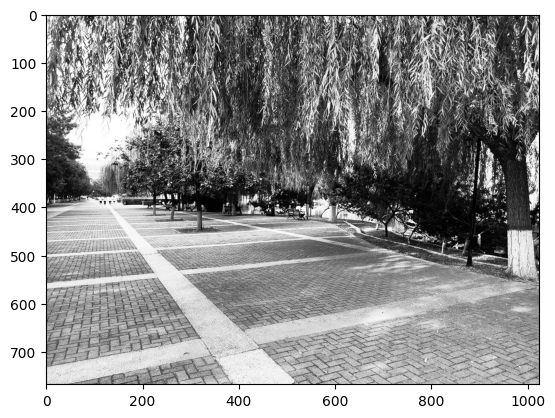

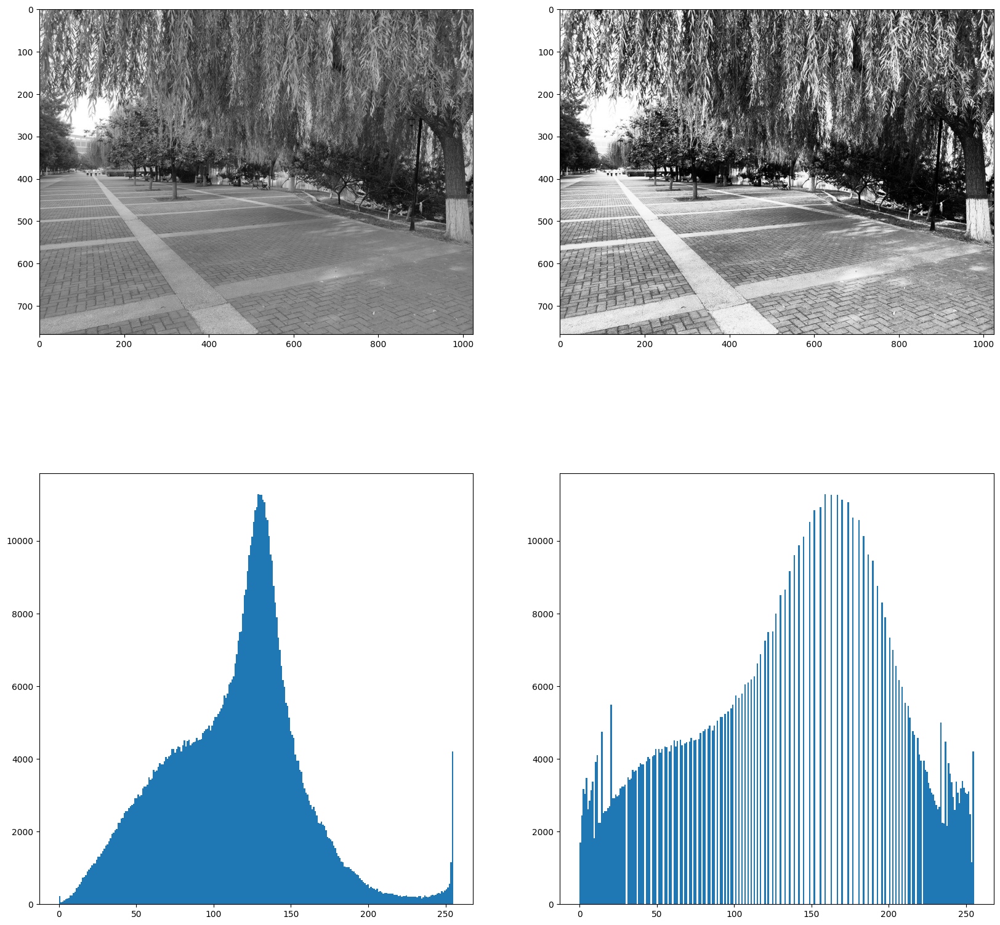

In [2]:
import numpy as np 
import matplotlib.pyplot as plt
import cv2 

path = '/home/aistudio/work/'
image_gray = cv2.imread(path + 'campus_1024_768_gray.jpg',0)
print(image_gray.shape)
plt.imshow(image_gray,'gray')
plt.show()

equalized_image_gray = cv2.equalizeHist(image_gray)

plt.imshow(equalized_image_gray,'gray')
plt.show()

plt.figure(figsize=(20,20))
plt.subplot(2,2,1)
plt.imshow(image_gray,'gray')
plt.subplot(2,2,2)
plt.imshow(equalized_image_gray,'gray')
plt.subplot(2,2,3)
plt.hist(image_gray.ravel(),256,[0,255])
plt.subplot(2,2,4)
plt.hist(equalized_image_gray.ravel(),256,[0,255])
plt.show()

(768, 1024)


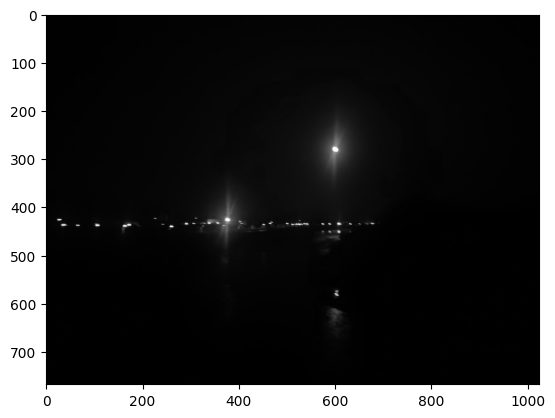

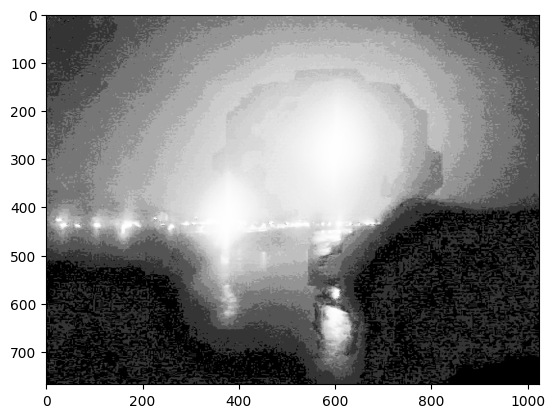

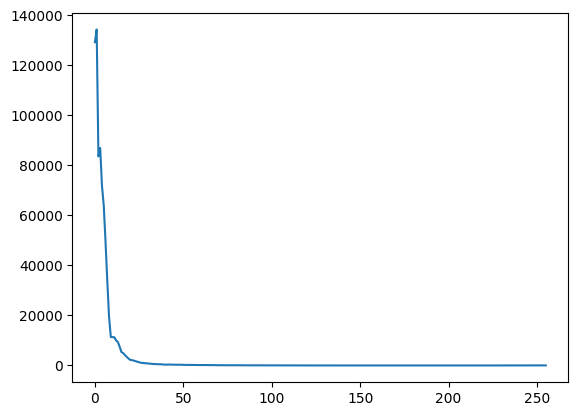

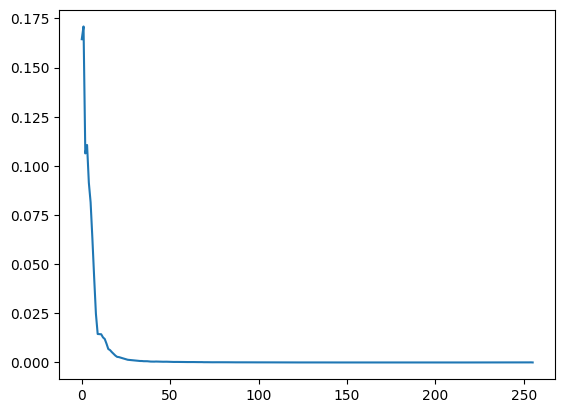

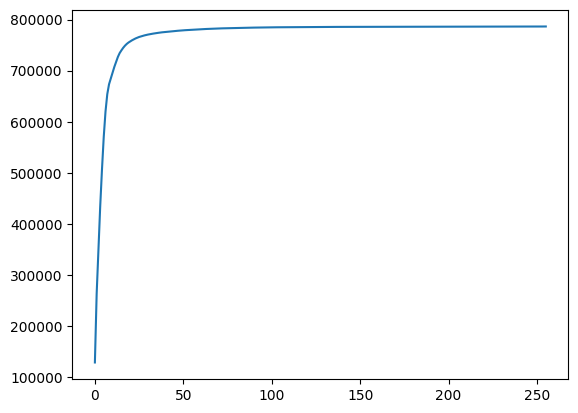

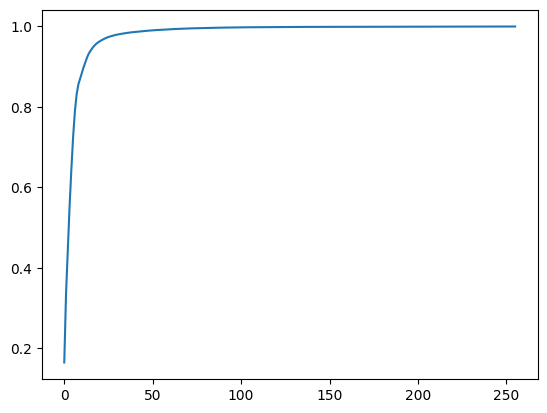

In [3]:
import numpy as np 
import matplotlib.pyplot as plt
import cv2 

def histogram(image_gray):
    rows,cols = image_gray.shape
    assert image_gray.dtype == np.uint8
    originHist = np.zeros((256,),np.int32)
    for i in range(0,rows):
        for j in range(0,cols):
            gray_value = image_gray[i,j]
            originHist[gray_value] = originHist[gray_value] + 1
    return originHist 

def pdf(image_gray):
    rows,cols = image_gray.shape    
    assert image_gray.dtype == np.uint8
    totalPixel = rows*cols
    originHist = histogram(image_gray)
    pdf_list = np.zeros((256,),np.float64)
    pdf_list = originHist.astype(np.float64)/float(totalPixel)
    return pdf_list


def cumulative_histogram(image_gray):
    originHist = histogram(image_gray)
    cumuHist = originHist.copy()
    summ = 0
    for i in range(0,len(originHist)):
        summ = summ + originHist[i]
        cumuHist[i] = summ
    return cumuHist



def cdf(image_gray):
    rows,cols = image_gray.shape    
    assert image_gray.dtype == np.uint8
    totalPixel = rows*cols
    cumuHist = cumulative_histogram(image_gray)
    cdf_list = np.zeros((256,),np.float64)
    cdf_list = cumuHist.astype(np.float64)/float(totalPixel)
    return cdf_list


def equlized_hist(image_gray):
    rows,cols = image_gray.shape
    assert image_gray.dtype == np.uint8
    image_equalized = np.zeros_like(image_gray,dtype=np.uint8)
    cdf_list = cdf(image_gray)
    for i in range(0,rows):
        for j in range(0,cols):
            value = image_gray[i,j]
            new_value = cdf_list[value] * 255.0
            image_equalized[i,j]=int(new_value)
    return image_equalized




path = '/home/aistudio/work/'
image_bgr = cv2.imread(path + 'wangxianqiao_1024_768.jpg')
image_gray = cv2.cvtColor(image_bgr,cv2.COLOR_BGR2GRAY)
print(image_gray.shape)
plt.imshow(image_gray,'gray')
plt.show()
plt.imshow(equlized_hist(image_gray),'gray')
plt.show()
plt.plot(histogram(image_gray))
plt.show()
plt.plot(pdf(image_gray))
plt.show()
plt.plot(cumulative_histogram(image_gray))
plt.show()
plt.plot(cdf(image_gray))
plt.show()





(768, 1024)


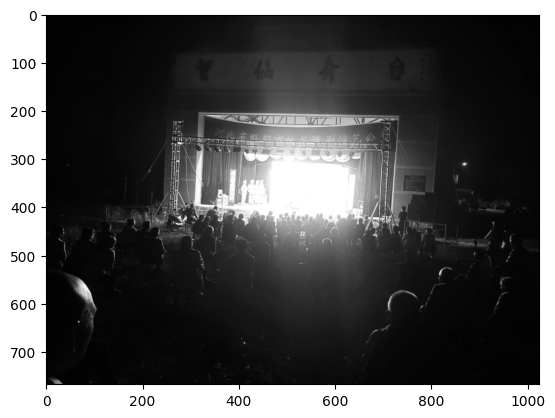

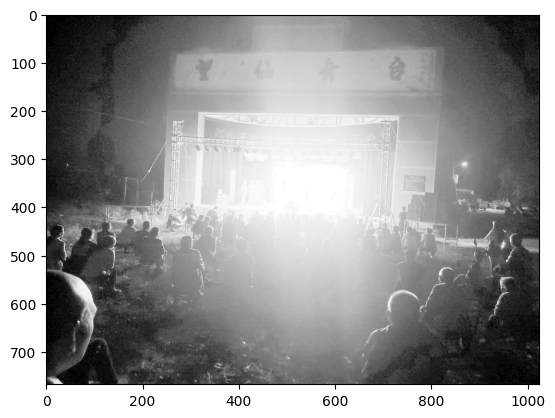

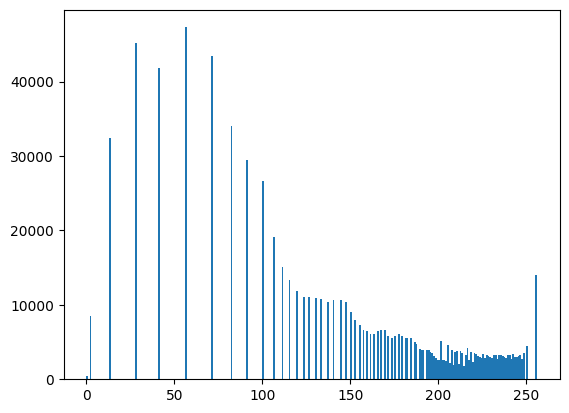

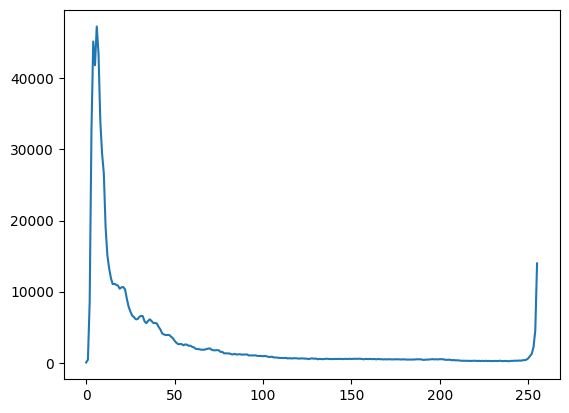

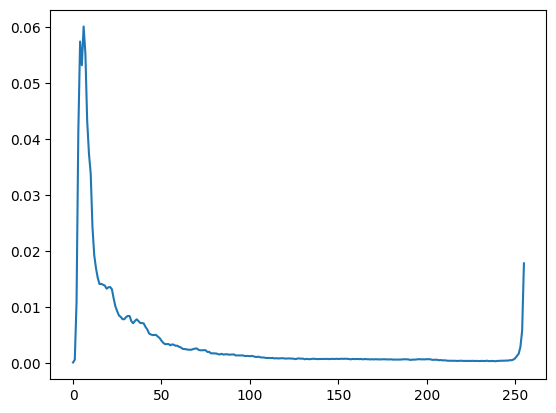

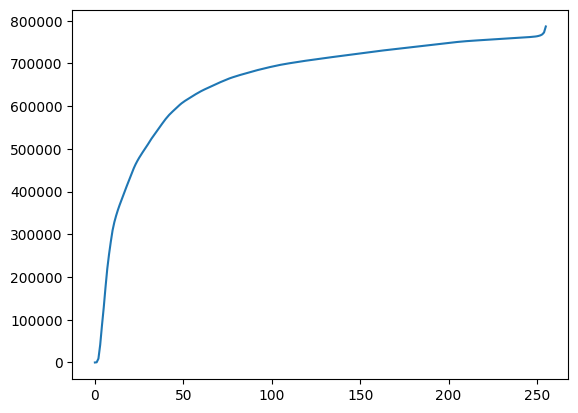

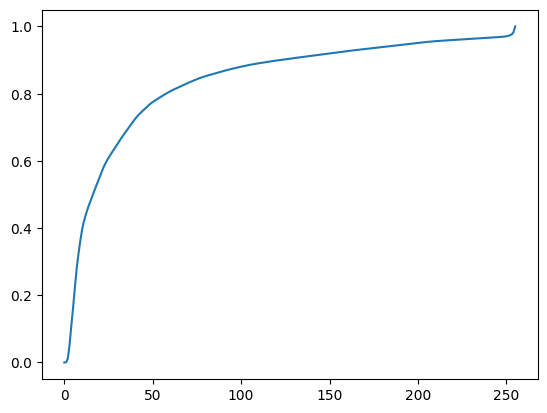

In [4]:
import numpy as np 
import matplotlib.pyplot as plt
import cv2 
path = '/home/aistudio/work/'
image_bgr = cv2.imread(path + 'wangxianwutai_1024_768.jpg')
image_gray = cv2.cvtColor(image_bgr,cv2.COLOR_BGR2GRAY)
image_equalized = equlized_hist(image_gray)
print(image_gray.shape)
plt.imshow(image_gray,'gray')
plt.show()
plt.imshow(equlized_hist(image_gray),'gray')
plt.show()

plt.hist(image_equalized.ravel(),256,[0,256])
plt.show()

plt.plot(histogram(image_gray))
plt.show()
plt.plot(pdf(image_gray))
plt.show()
plt.plot(cumulative_histogram(image_gray))
plt.show()
plt.plot(cdf(image_gray))
plt.show()

# 例4-15

(96, 128)


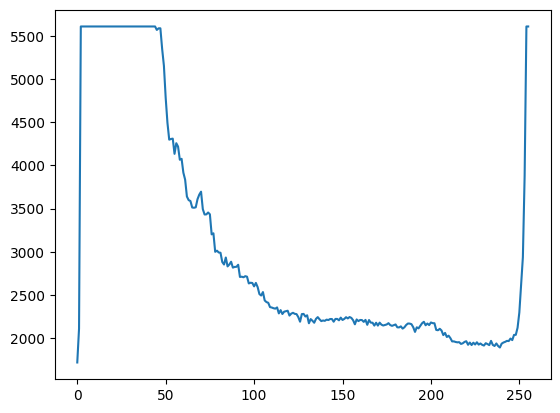

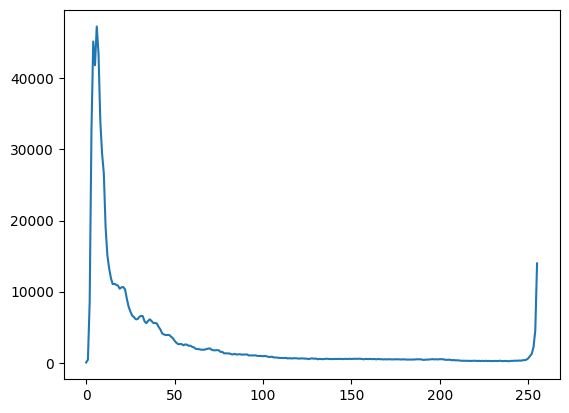

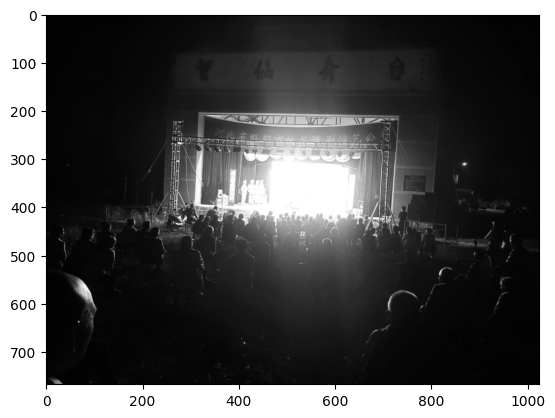

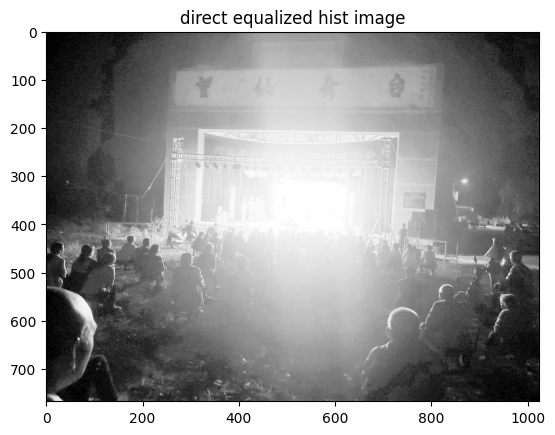

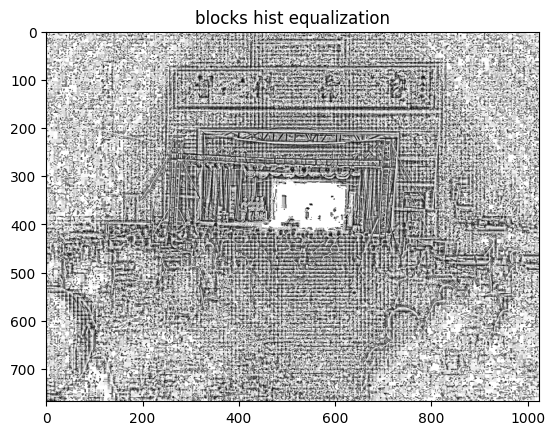

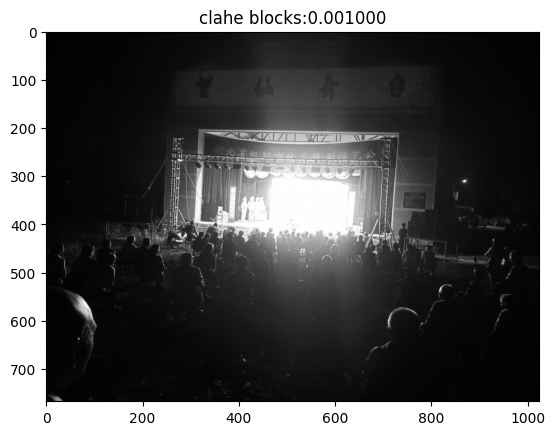

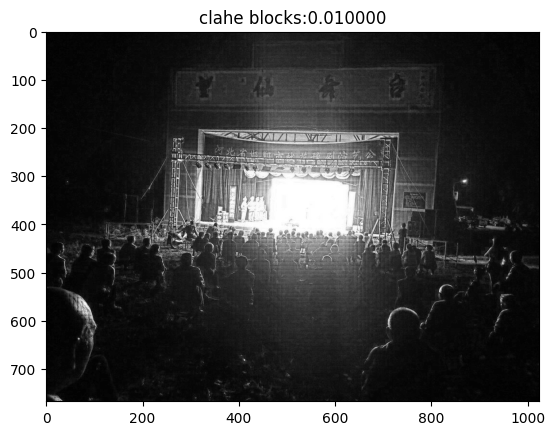

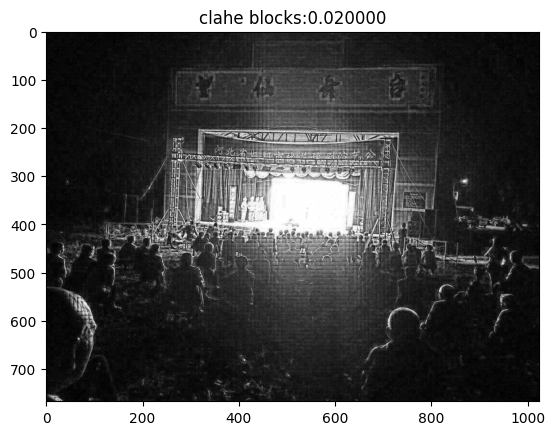

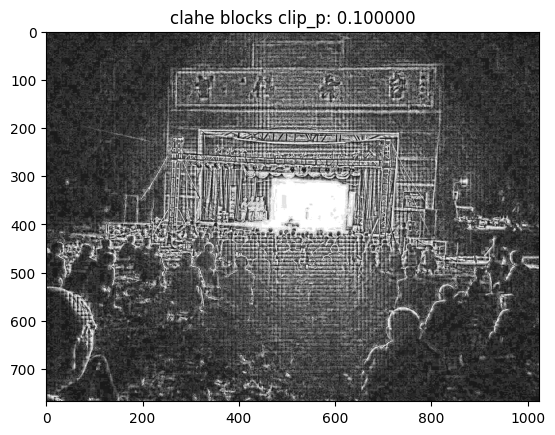

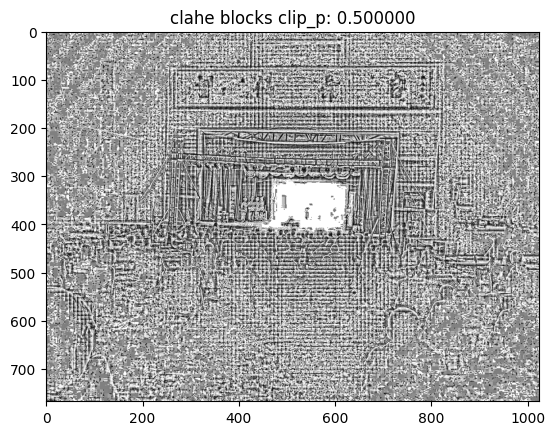

In [7]:
import numpy as np 
import matplotlib.pyplot as plt
import cv2 



def clahe_histogram(image_gray,clip_p=0.1):
    # clip_p totoal num 
    rows,cols = image_gray.shape
    assert image_gray.dtype == np.uint8
    originHist = np.zeros((256,),np.int32)
    for i in range(0,rows):
        for j in range(0,cols):
            gray_value = image_gray[i,j]
            originHist[gray_value] = originHist[gray_value] + 1
    clip_p_nums = rows*cols*clip_p
    clahe_hist = originHist.copy()
    clahe_hist = clahe_hist.astype(np.float64)
    diff_sum = 0
    #print(clahe_hist)
    for i in range(0,len(clahe_hist)):
        if(clahe_hist[i]>clip_p_nums):
            diff_sum = diff_sum + clahe_hist[i]-clip_p_nums
            clahe_hist[i]=clip_p_nums    
                
    aver_diff_sum = diff_sum/256.0
    clahe_hist = clahe_hist + aver_diff_sum
    #print(clahe_hist)
    #print(clahe_hist.sum())
    return clahe_hist 

def clahe_pdf(image_gray,clip_p=0.1):
    rows,cols = image_gray.shape    
    assert image_gray.dtype == np.uint8
    totalPixel = rows*cols
    originHist = clahe_histogram(image_gray,clip_p)
    pdf_list = np.zeros((256,),np.float64)
    pdf_list = originHist.astype(np.float64)/float(totalPixel)
    return pdf_list
    
def clahe_cumulative_histogram(image_gray,clip_p=0.1):
    originHist = clahe_histogram(image_gray,clip_p)
    cumuHist = originHist.copy()
    summ = 0
    for i in range(0,len(originHist)):
        summ = summ + originHist[i]
        cumuHist[i] = summ
    return cumuHist

def clahe_cdf(image_gray,clip_p=0.1):
    rows,cols = image_gray.shape    
    assert image_gray.dtype == np.uint8
    totalPixel = rows*cols
    cumuHist = clahe_cumulative_histogram(image_gray,clip_p)
    cdf_list = np.zeros((256,),np.float64)
    cdf_list = cumuHist.astype(np.float64)/float(totalPixel)
    return cdf_list


def histogram(image_gray):
    rows,cols = image_gray.shape
    assert image_gray.dtype == np.uint8
    originHist = np.zeros((256,),np.int32)
    for i in range(0,rows):
        for j in range(0,cols):
            gray_value = image_gray[i,j]
            originHist[gray_value] = originHist[gray_value] + 1
    return originHist 

def pdf(image_gray):
    rows,cols = image_gray.shape    
    assert image_gray.dtype == np.uint8
    totalPixel = rows*cols
    originHist = histogram(image_gray)
    pdf_list = np.zeros((256,),np.float64)
    pdf_list = originHist.astype(np.float64)/float(totalPixel)
    return pdf_list

def cumulative_histogram(image_gray):
    originHist = histogram(image_gray)
    cumuHist = originHist.copy()
    summ = 0
    for i in range(0,len(originHist)):
        summ = summ + originHist[i]
        cumuHist[i] = summ
    return cumuHist

def cdf(image_gray):
    rows,cols = image_gray.shape    
    assert image_gray.dtype == np.uint8
    totalPixel = rows*cols
    cumuHist = cumulative_histogram(image_gray)
    cdf_list = np.zeros((256,),np.float64)
    cdf_list = cumuHist.astype(np.float64)/float(totalPixel)
    return cdf_list

def equlized_hist(image_gray):
    rows,cols = image_gray.shape
    assert image_gray.dtype == np.uint8
    image_equalized = np.zeros_like(image_gray,dtype=np.uint8)
    cdf_list = cdf(image_gray)
    for i in range(0,rows):
        for j in range(0,cols):
            value = image_gray[i,j]
            new_value = cdf_list[value] * 255.0
            image_equalized[i,j]=int(new_value)
    return image_equalized


def clahe_equlized_hist(image_gray,clip_p =0.1):
    rows,cols = image_gray.shape
    assert image_gray.dtype == np.uint8
    image_equalized = np.zeros_like(image_gray,dtype=np.uint8)
    cdf_list = clahe_cdf(image_gray,clip_p)
    for i in range(0,rows):
        for j in range(0,cols):
            value = image_gray[i,j]
            new_value = cdf_list[value] * 255.0
            image_equalized[i,j]=int(new_value)
    return image_equalized


def tiles_image(image_gray):
    size = int(8)
    rows,cols = image_gray.shape
    assert image_gray.dtype == np.uint8
    assert rows%size == 0
    assert cols%size == 0
    row_tiles = int(rows/size)
    col_tiles = int(cols/size)
    return (row_tiles,col_tiles)

def adapt_hist_eq(image_gray):
    size = int(8)
    rows,cols = tiles_image(image_gray)
    assert image_gray.dtype == np.uint8
    assert rows%size == 0
    assert cols%size == 0
    image_copy = image_gray.copy()
    image_he = np.zeros_like(image_gray,dtype = np.uint8)
    for i in range(0,rows):
        for j in range(0,cols):
            roi = image_copy[i*size:(i+1)*size,j*size:(j+1)*size].copy()
            roi_he = equlized_hist(roi.copy())
            #print(i,j)
            #print(roi)
            #print(roi_he)
            image_he[i*size:(i+1)*size,j*size:(j+1)*size] = roi_he[:,:]
    return image_he

def clahe_adapt_hist_eq(image_gray,clip_p=0.1):
    size = int(8)
    rows,cols = tiles_image(image_gray)
    assert image_gray.dtype == np.uint8
    assert rows%size == 0
    assert cols%size == 0
    image_copy = image_gray.copy()
    image_he = np.zeros_like(image_gray,dtype = np.uint8)
    for i in range(0,rows):
        for j in range(0,cols):
            roi = image_copy[i*size:(i+1)*size,j*size:(j+1)*size].copy()
            roi_he = clahe_equlized_hist(roi.copy(),clip_p)
            #print(i,j)
            #print(roi)
            #print(roi_he)
            image_he[i*size:(i+1)*size,j*size:(j+1)*size] = roi_he[:,:]
    return image_he




print(tiles_image(image_gray))

path = '/home/aistudio/work/'
image_bgr = cv2.imread(path + 'wangxianwutai_1024_768.jpg')
#image_bgr = cv2.imread(path + 'campus_1024_768_gray.jpg')
image_gray = cv2.cvtColor(image_bgr,cv2.COLOR_BGR2GRAY)


clip_p = 0.005
plt.plot(clahe_histogram(image_gray,clip_p ))
plt.show()
plt.plot(histogram(image_gray))
plt.show()


plt.imshow(image_gray,'gray')
plt.show()
plt.imshow(equlized_hist(image_gray),'gray')
plt.title('direct equalized hist image')
plt.show()
plt.imshow(adapt_hist_eq(image_gray),'gray')
plt.title('blocks hist equalization')
plt.show()

clip_p = 0.001
plt.imshow(clahe_adapt_hist_eq(image_gray,clip_p),'gray')
plt.title('clahe blocks:%f'%clip_p)
plt.show()


clip_p = 0.01
plt.imshow(clahe_adapt_hist_eq(image_gray,clip_p),'gray')
plt.title('clahe blocks:%f'%clip_p)
plt.show()

clip_p = 0.02
plt.imshow(clahe_adapt_hist_eq(image_gray,clip_p),'gray')
plt.title('clahe blocks:%f'%clip_p)
plt.show()

clip_p = 0.1
plt.imshow(clahe_adapt_hist_eq(image_gray,clip_p),'gray')
plt.title('clahe blocks clip_p: %f'%clip_p)
plt.show()

clip_p = 0.5
plt.imshow(clahe_adapt_hist_eq(image_gray,clip_p),'gray')
plt.title('clahe blocks clip_p: %f'%clip_p)
plt.show()



# 例4-16

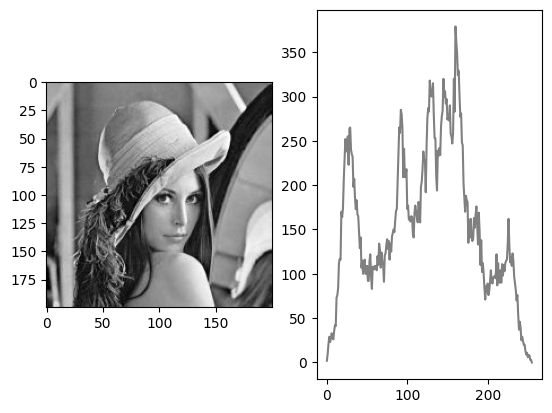

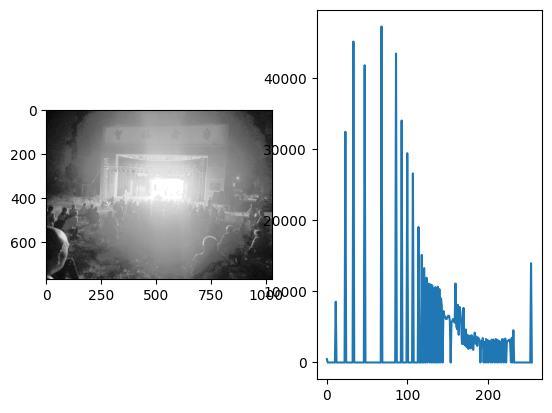

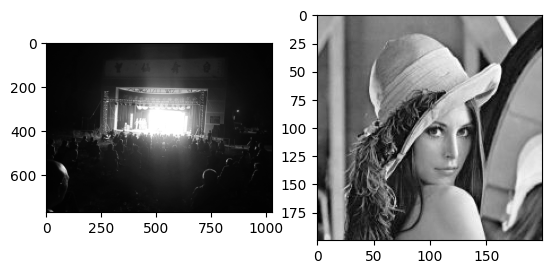

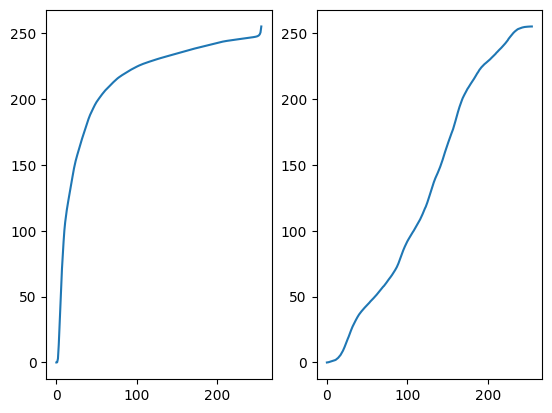

In [8]:
import numpy as np 
import matplotlib.pyplot as plt
import cv2 


def histogram(image_gray):
    rows,cols = image_gray.shape
    assert image_gray.dtype == np.uint8
    originHist = np.zeros((256,),np.int32)
    for i in range(0,rows):
        for j in range(0,cols):
            gray_value = image_gray[i,j]
            originHist[gray_value] = originHist[gray_value] + 1
    return originHist 

def pdf(image_gray):
    rows,cols = image_gray.shape    
    assert image_gray.dtype == np.uint8
    totalPixel = rows*cols
    originHist = histogram(image_gray)
    pdf_list = np.zeros((256,),np.float64)
    pdf_list = originHist.astype(np.float64)/float(totalPixel)
    return pdf_list

def cumulative_histogram(image_gray):
    originHist = histogram(image_gray)
    cumuHist = originHist.copy()
    summ = 0
    for i in range(0,len(originHist)):
        summ = summ + originHist[i]
        cumuHist[i] = summ
    return cumuHist

def cdf(image_gray):
    rows,cols = image_gray.shape    
    assert image_gray.dtype == np.uint8
    totalPixel = rows*cols
    cumuHist = cumulative_histogram(image_gray)
    cdf_list = np.zeros((256,),np.float64)
    cdf_list = cumuHist.astype(np.float64)/float(totalPixel)
    return cdf_list



def match_histogram(image_gray_source, image_gray_reference): 
    assert image_gray_source.dtype == np.uint8
    assert image_gray_reference.dtype  == np.uint8
    rows,cols = image_gray_source.shape
    match_image = np.zeros((rows,cols),dtype = np.uint8)
    z_k = np.zeros((256,),dtype = np.uint8)
    cdf_r = cdf(image_gray_source)*255
    cdf_r =cdf_r.astype(np.uint8)
    cdf_z = cdf(image_gray_reference)*255
    cdf_z = cdf_z.astype(np.uint8)
    Tr = cdf_r
    Gz = cdf_z
    for i in range(0,256):
        s = Tr[i]
        diff_min = 10000
        diff_min_index = -10000    
        for k in range(0,256):
            diff_tmp = np.abs(int(Gz[k])-int(s))
            if(diff_min>diff_tmp):
                diff_min = diff_tmp
                diff_min_index = k            
        z_k[i] = diff_min_index 
    for i in range(0,rows):
        for j in range(0,cols):
            r = image_gray_source[i,j]
            match_image[i,j] = z_k[r]
    
    return match_image



path = '/home/aistudio/work/'
image_bgr_source = cv2.imread(path + 'wangxianwutai_1024_768.jpg')
#image_bgr_reference = cv2.imread(path + 'campus_1024_768_gray.jpg')
image_bgr_reference = cv2.imread(path + 'lena.jpg')
image_gray_source = cv2.cvtColor(image_bgr_source,cv2.COLOR_BGR2GRAY)
image_gray_reference =  cv2.cvtColor(image_bgr_reference,cv2.COLOR_BGR2GRAY)
match_image =match_histogram(image_gray_source, image_gray_reference)

plt.subplot(1,2,1)
plt.imshow(image_gray_reference,'gray')
plt.subplot(1,2,2)
plt.plot(histogram(image_gray_reference),'gray')
plt.show()

plt.subplot(1,2,1)
plt.imshow(match_image,'gray')
plt.subplot(1,2,2)
plt.plot(histogram(match_image))
plt.show()


plt.subplot(1,2,1)
plt.imshow(image_gray_source,'gray')
plt.subplot(1,2,2)
plt.imshow(image_gray_reference,'gray')
plt.show()

plt.subplot(1,2,1)
plt.plot(cdf(image_gray_source)*255)
plt.subplot(1,2,2)
plt.plot(cdf(image_gray_reference)*255)
plt.show()





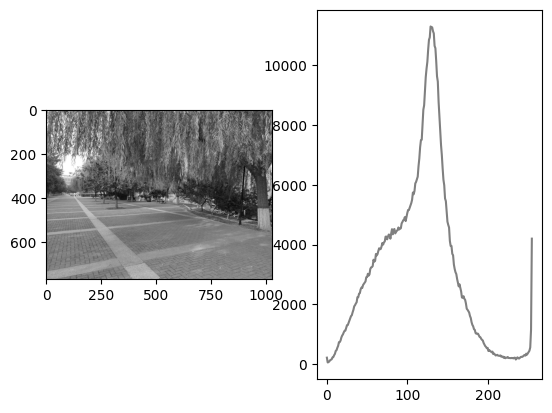

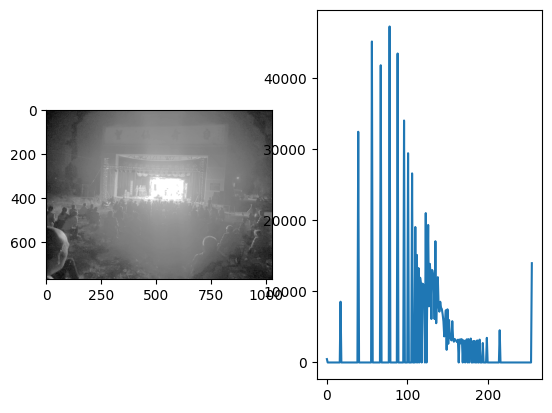

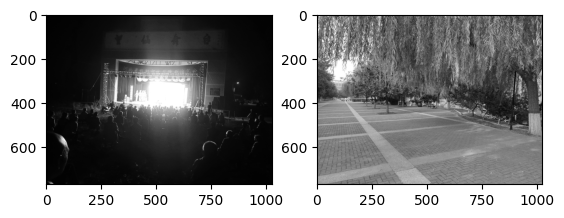

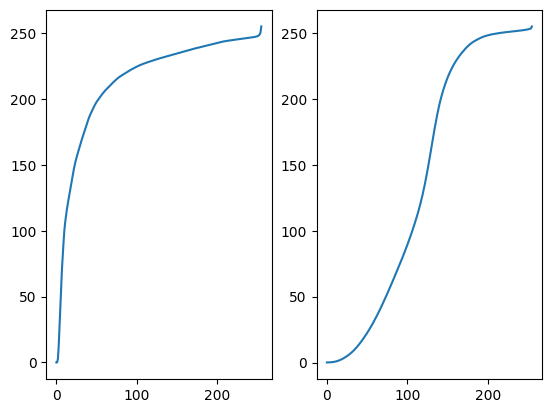

In [9]:
import numpy as np 
import matplotlib.pyplot as plt
import cv2 


def histogram(image_gray):
    rows,cols = image_gray.shape
    assert image_gray.dtype == np.uint8
    originHist = np.zeros((256,),np.int32)
    for i in range(0,rows):
        for j in range(0,cols):
            gray_value = image_gray[i,j]
            originHist[gray_value] = originHist[gray_value] + 1
    return originHist 

def pdf(image_gray):
    rows,cols = image_gray.shape    
    assert image_gray.dtype == np.uint8
    totalPixel = rows*cols
    originHist = histogram(image_gray)
    pdf_list = np.zeros((256,),np.float64)
    pdf_list = originHist.astype(np.float64)/float(totalPixel)
    return pdf_list

def cumulative_histogram(image_gray):
    originHist = histogram(image_gray)
    cumuHist = originHist.copy()
    summ = 0
    for i in range(0,len(originHist)):
        summ = summ + originHist[i]
        cumuHist[i] = summ
    return cumuHist

def cdf(image_gray):
    rows,cols = image_gray.shape    
    assert image_gray.dtype == np.uint8
    totalPixel = rows*cols
    cumuHist = cumulative_histogram(image_gray)
    cdf_list = np.zeros((256,),np.float64)
    cdf_list = cumuHist.astype(np.float64)/float(totalPixel)
    return cdf_list



def match_histogram(image_gray_source, image_gray_reference): 
    assert image_gray_source.dtype == np.uint8
    assert image_gray_reference.dtype  == np.uint8
    rows,cols = image_gray_source.shape
    match_image = np.zeros((rows,cols),dtype = np.uint8)
    z_k = np.zeros((256,),dtype = np.uint8)
    cdf_r = cdf(image_gray_source)*255
    cdf_r =cdf_r.astype(np.uint8)
    cdf_z = cdf(image_gray_reference)*255
    cdf_z = cdf_z.astype(np.uint8)
    Tr = cdf_r
    Gz = cdf_z
    for i in range(0,256):
        s = Tr[i]
        diff_min = 10000
        diff_min_index = -10000    
        for k in range(0,256):
            diff_tmp = np.abs(int(Gz[k])-int(s))
            if(diff_min>diff_tmp):
                diff_min = diff_tmp
                diff_min_index = k            
        z_k[i] = diff_min_index 
    for i in range(0,rows):
        for j in range(0,cols):
            r = image_gray_source[i,j]
            match_image[i,j] = z_k[r]
    
    return match_image



path = '/home/aistudio/work/'
image_bgr_source = cv2.imread(path + 'wangxianwutai_1024_768.jpg')
image_bgr_reference = cv2.imread(path + 'campus_1024_768_gray.jpg')
#image_bgr_reference = cv2.imread(path + 'lena.jpg')
image_gray_source = cv2.cvtColor(image_bgr_source,cv2.COLOR_BGR2GRAY)
image_gray_reference =  cv2.cvtColor(image_bgr_reference,cv2.COLOR_BGR2GRAY)

match_image =match_histogram(image_gray_source, image_gray_reference)

plt.subplot(1,2,1)
plt.imshow(image_gray_reference,'gray')
plt.subplot(1,2,2)
plt.plot(histogram(image_gray_reference),'gray')
plt.show()

plt.subplot(1,2,1)
plt.imshow(match_image,'gray')
plt.subplot(1,2,2)
plt.plot(histogram(match_image))
plt.show()


plt.subplot(1,2,1)
plt.imshow(image_gray_source,'gray')
plt.subplot(1,2,2)
plt.imshow(image_gray_reference,'gray')
plt.show()

plt.subplot(1,2,1)
plt.plot(cdf(image_gray_source)*255)
plt.subplot(1,2,2)
plt.plot(cdf(image_gray_reference)*255)
plt.show()





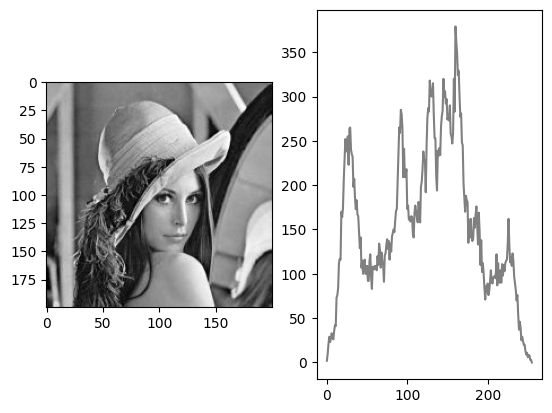

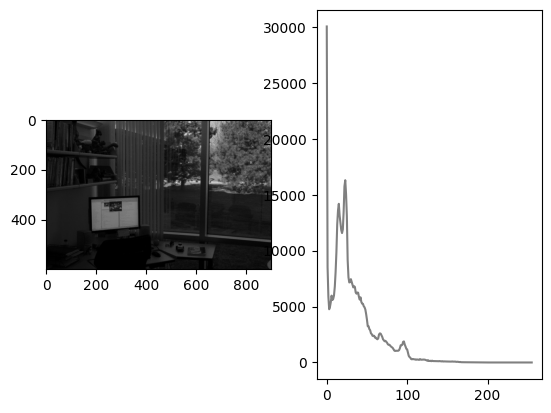

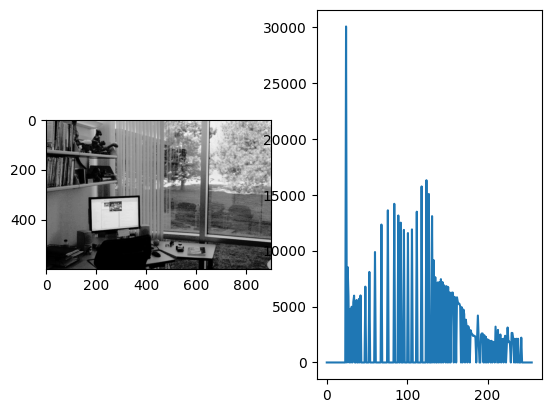

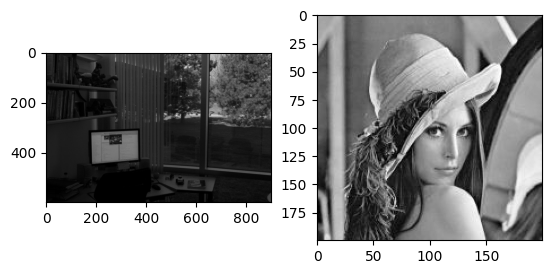

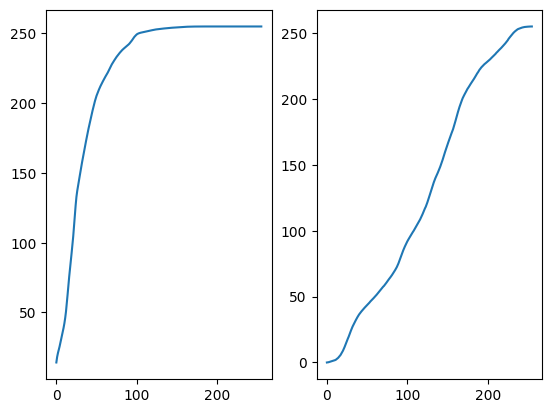

In [10]:
import numpy as np 
import matplotlib.pyplot as plt
import cv2 


def histogram(image_gray):
    rows,cols = image_gray.shape
    assert image_gray.dtype == np.uint8
    originHist = np.zeros((256,),np.int32)
    for i in range(0,rows):
        for j in range(0,cols):
            gray_value = image_gray[i,j]
            originHist[gray_value] = originHist[gray_value] + 1
    return originHist 

def pdf(image_gray):
    rows,cols = image_gray.shape    
    assert image_gray.dtype == np.uint8
    totalPixel = rows*cols
    originHist = histogram(image_gray)
    pdf_list = np.zeros((256,),np.float64)
    pdf_list = originHist.astype(np.float64)/float(totalPixel)
    return pdf_list

def cumulative_histogram(image_gray):
    originHist = histogram(image_gray)
    cumuHist = originHist.copy()
    summ = 0
    for i in range(0,len(originHist)):
        summ = summ + originHist[i]
        cumuHist[i] = summ
    return cumuHist

def cdf(image_gray):
    rows,cols = image_gray.shape    
    assert image_gray.dtype == np.uint8
    totalPixel = rows*cols
    cumuHist = cumulative_histogram(image_gray)
    cdf_list = np.zeros((256,),np.float64)
    cdf_list = cumuHist.astype(np.float64)/float(totalPixel)
    return cdf_list



def match_histogram(image_gray_source, image_gray_reference): 
    assert image_gray_source.dtype == np.uint8
    assert image_gray_reference.dtype  == np.uint8
    rows,cols = image_gray_source.shape
    match_image = np.zeros((rows,cols),dtype = np.uint8)
    z_k = np.zeros((256,),dtype = np.uint8)
    cdf_r = cdf(image_gray_source)*255
    cdf_r =cdf_r.astype(np.uint8)
    cdf_z = cdf(image_gray_reference)*255
    cdf_z = cdf_z.astype(np.uint8)
    Tr = cdf_r
    Gz = cdf_z
    for i in range(0,256):
        s = Tr[i]
        diff_min = 10000
        diff_min_index = -10000    
        for k in range(0,256):
            diff_tmp = np.abs(int(Gz[k])-int(s))
            if(diff_min>diff_tmp):
                diff_min = diff_tmp
                diff_min_index = k            
        z_k[i] = diff_min_index 
    for i in range(0,rows):
        for j in range(0,cols):
            r = image_gray_source[i,j]
            match_image[i,j] = z_k[r]
    
    return match_image



path = '/home/aistudio/work/'
image_bgr_source = cv2.imread(path + 'office_2.jpg')
#image_bgr_reference = cv2.imread(path + 'campus_1024_768_gray.jpg')
image_bgr_reference = cv2.imread(path + 'lena.jpg')
image_gray_source = cv2.cvtColor(image_bgr_source,cv2.COLOR_BGR2GRAY)
image_gray_reference =  cv2.cvtColor(image_bgr_reference,cv2.COLOR_BGR2GRAY)

match_image =match_histogram(image_gray_source, image_gray_reference)

plt.subplot(1,2,1)
plt.imshow(image_gray_reference,'gray')
plt.subplot(1,2,2)
plt.plot(histogram(image_gray_reference),'gray')
plt.show()

plt.subplot(1,2,1)
plt.imshow(image_gray_source,'gray')
plt.subplot(1,2,2)
plt.plot(histogram(image_gray_source),'gray')
plt.show()

plt.subplot(1,2,1)
plt.imshow(match_image,'gray')
plt.subplot(1,2,2)
plt.plot(histogram(match_image))
plt.show()


plt.subplot(1,2,1)
plt.imshow(image_gray_source,'gray')
plt.subplot(1,2,2)
plt.imshow(image_gray_reference,'gray')
plt.show()

plt.subplot(1,2,1)
plt.plot(cdf(image_gray_source)*255)
plt.subplot(1,2,2)
plt.plot(cdf(image_gray_reference)*255)
plt.show()





# 例4-17 彩色直方图规定化

<class 'numpy.ndarray'>
uint8


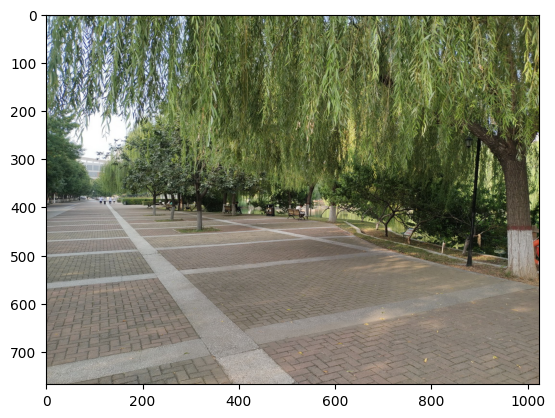

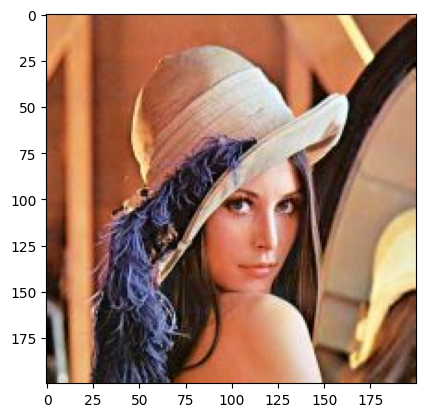

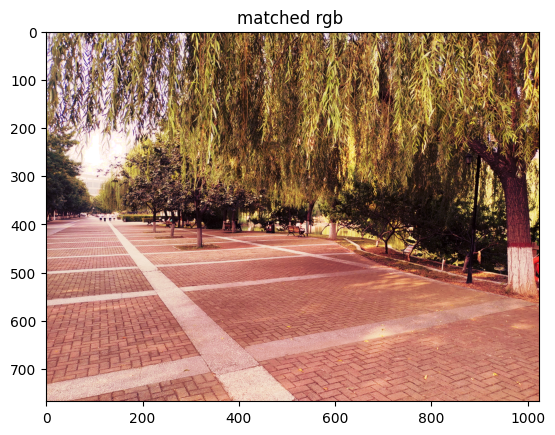

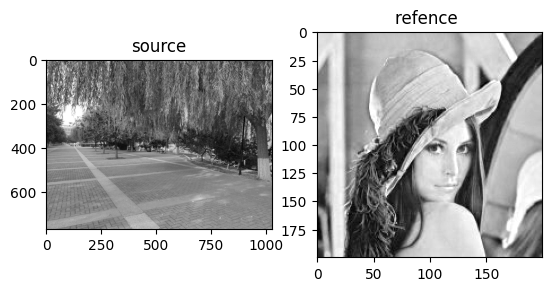

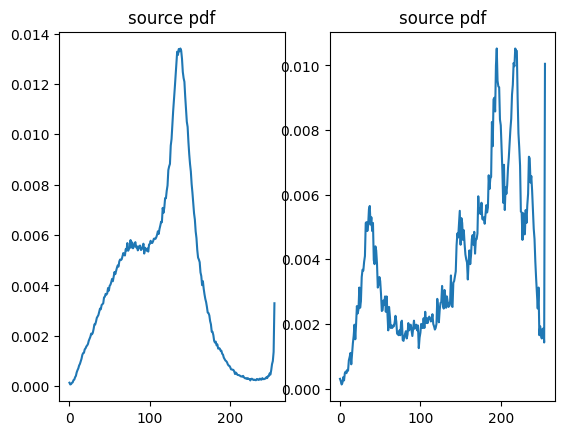

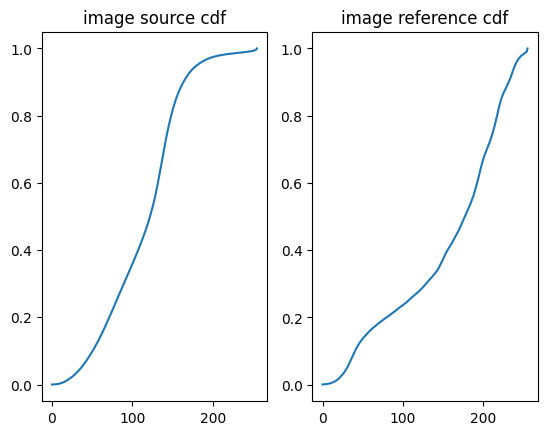

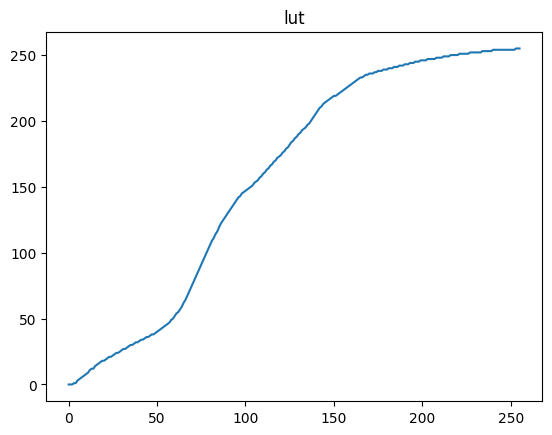

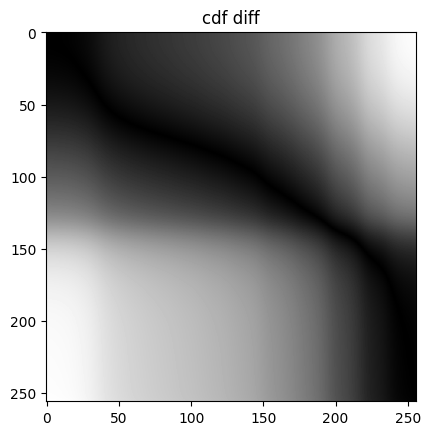

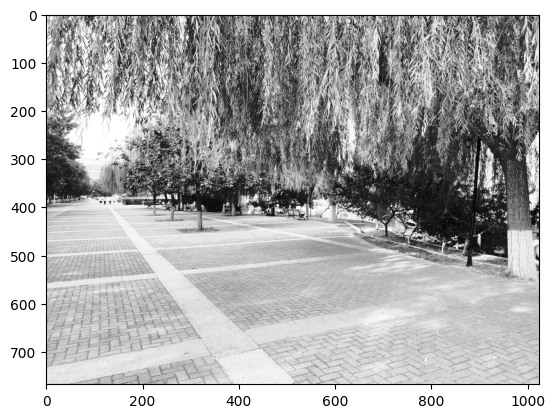

In [14]:
import numpy as np 
import matplotlib.pyplot as plt
import cv2 


path = '/home/aistudio/work/'
#image_bgr_source = cv2.imread(path + 'office_2.jpg')
image_bgr_source = cv2.imread(path + 'campus_1024_768.jpg')
image_bgr_reference = cv2.imread(path + 'lena.jpg')
im_rgb_source = cv2.cvtColor(image_bgr_source, cv2.COLOR_BGR2RGB)
im_rgb_reference = cv2.cvtColor(image_bgr_reference,cv2.COLOR_BGR2RGB)
im_r_src,im_g_src, im_b_src = cv2.split(im_rgb_source)
im_r_ref,im_g_ref,im_b_ref = cv2.split(im_rgb_reference)



def match_image_channel(im_r_src,im_r_ref):
    im_r_src_hist,bins_edge  = np.histogram(im_r_src.ravel(),256,[0,256])
    im_r_src_cumhist = np.cumsum(im_r_src_hist.copy())
    im_r_src_pdf = im_r_src_hist/np.sum(im_r_src_hist)
    im_r_src_cdf = im_r_src_cumhist/im_r_src_cumhist[-1]

    im_r_ref_hist,bins_edge  = np.histogram(im_r_ref.ravel(),256,[0,256])
    im_r_ref_cumhist = np.cumsum(im_r_ref_hist.copy())
    im_r_ref_pdf = im_r_ref_hist/np.sum(im_r_ref_hist)
    im_r_ref_cdf = im_r_ref_cumhist/im_r_ref_cumhist[-1]

    cdf_r_diff = np.zeros((256,256),dtype = np.float64)

    for r in range(0,256):
        for z in range(0,256):
            cdf_r_diff[r,z] = np.abs(im_r_src_cdf[r] - im_r_ref_cdf[z])

    lut = np.zeros((256,),dtype = np.uint8)
    for r in range(0,256):
        cdf_list = cdf_r_diff[r,:]
        lut[r]= np.argmin(cdf_list)
    im_r_matched = cv2.LUT(im_r_src,lut)
    return im_r_matched,im_r_src_pdf,im_r_src_cdf,im_r_ref_pdf,im_r_ref_cdf,cdf_r_diff,lut

im_r_matched,im_r_src_pdf,im_r_src_cdf,im_r_ref_pdf,im_r_ref_cdf,cdf_r_diff,lut_r  = \
match_image_channel(im_r_src,im_r_ref)


im_g_matched,im_g_src_pdf,im_g_src_cdf,im_g_ref_pdf,im_g_ref_cdf,cdf_g_diff,lut_g  = \
match_image_channel(im_g_src,im_g_ref)


im_b_matched,im_b_src_pdf,im_b_src_cdf,im_b_ref_pdf,im_b_ref_cdf,cdf_b_diff,lut_b  = \
match_image_channel(im_b_src,im_b_ref)


im_rgb_matched = cv2.merge((im_r_matched,im_g_matched,im_b_matched))

print(type(im_rgb_matched))
print(im_rgb_matched.dtype)
plt.imshow(im_rgb_source)
plt.show()
plt.imshow(im_rgb_reference)
plt.show()
plt.imshow(im_rgb_matched)
plt.title('matched rgb ')
plt.show()


plt.subplot(1,2,1)
plt.imshow(im_r_src,'gray')
plt.title('source')
plt.subplot(1,2,2)
plt.imshow(im_r_ref,'gray')
plt.title('refence ')
plt.show()

plt.subplot(1,2,1)
plt.plot(im_r_src_pdf)
plt.title( 'source pdf')
plt.subplot(1,2,2)
plt.plot(im_r_ref_pdf)
plt.title('source pdf')
plt.show()

plt.subplot(1,2,1)
plt.plot(im_r_src_cdf)
plt.title('image source cdf')
plt.subplot(1,2,2)
plt.plot(im_r_ref_cdf)
plt.title('image reference cdf')
plt.show()

plt.plot(lut_r)
plt.title('lut')
plt.show()
plt.imshow(cdf_r_diff,'gray')
plt.title('cdf diff')
plt.show()

plt.imshow(im_r_matched,'gray')
plt.show()



<class 'numpy.ndarray'>
uint8


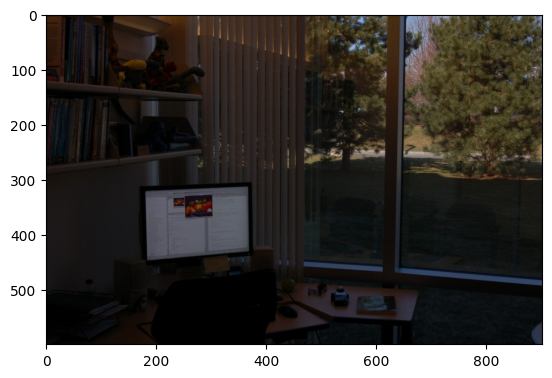

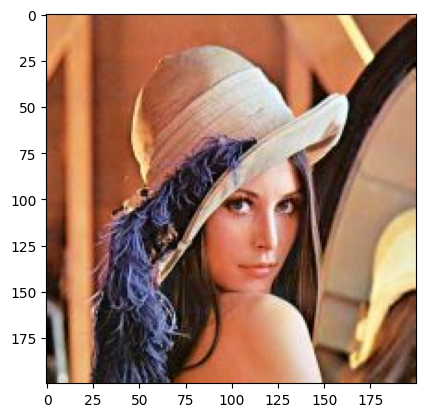

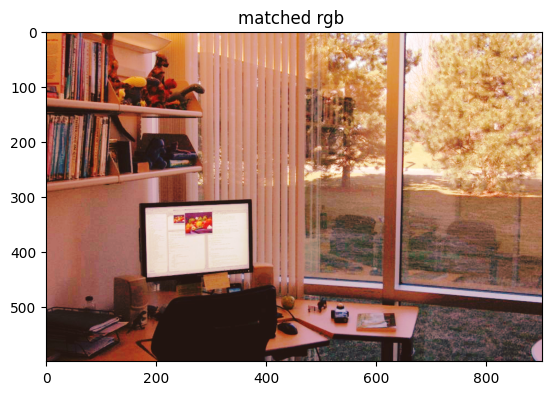

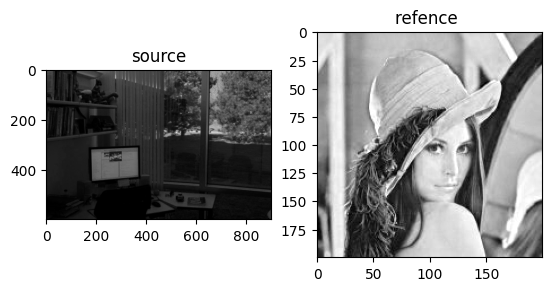

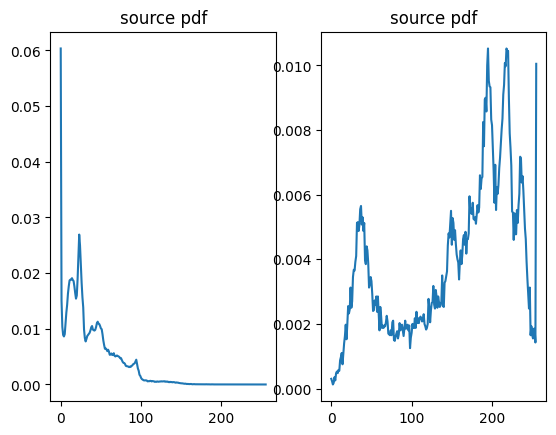

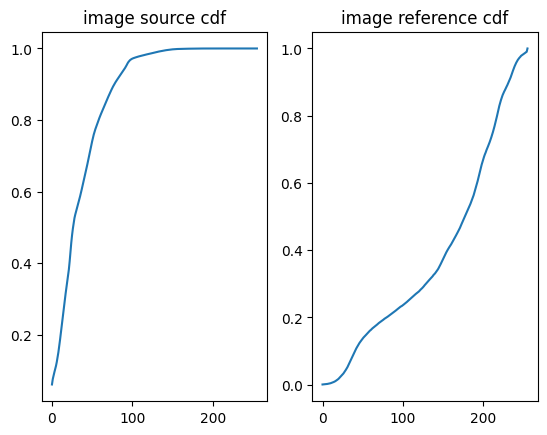

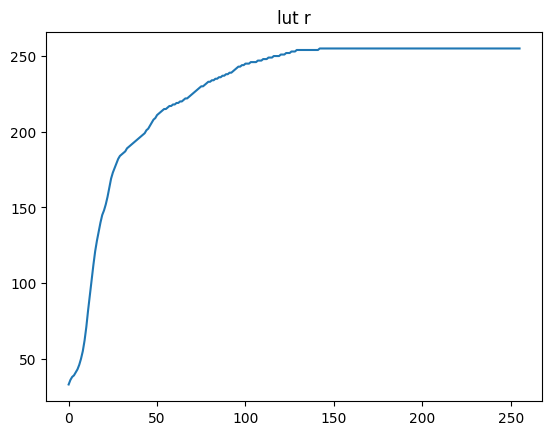

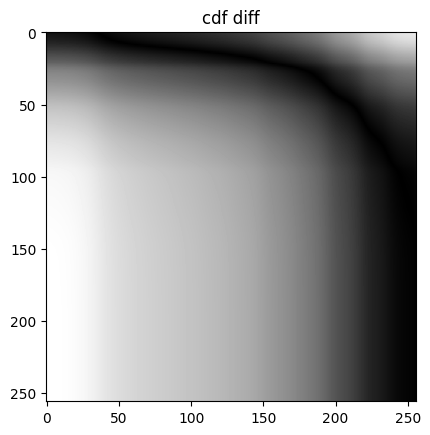

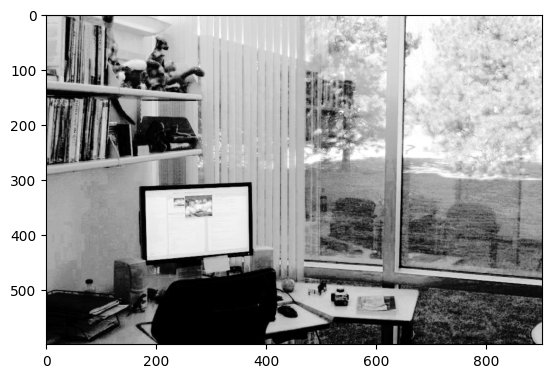

In [15]:
import numpy as np 
import matplotlib.pyplot as plt
import cv2 


path = '/home/aistudio/work/'
image_bgr_source = cv2.imread(path + 'office_2.jpg')
#image_bgr_source = cv2.imread(path + 'campus_1024_768.jpg')
image_bgr_reference = cv2.imread(path + 'lena.jpg')
im_rgb_source = cv2.cvtColor(image_bgr_source, cv2.COLOR_BGR2RGB)
im_rgb_reference = cv2.cvtColor(image_bgr_reference,cv2.COLOR_BGR2RGB)
im_r_src,im_g_src, im_b_src = cv2.split(im_rgb_source)
im_r_ref,im_g_ref,im_b_ref = cv2.split(im_rgb_reference)



def match_image_channel(im_r_src,im_r_ref):
    im_r_src_hist,bins_edge  = np.histogram(im_r_src.ravel(),256,[0,256])
    im_r_src_cumhist = np.cumsum(im_r_src_hist.copy())
    im_r_src_pdf = im_r_src_hist/np.sum(im_r_src_hist)
    im_r_src_cdf = im_r_src_cumhist/im_r_src_cumhist[-1]

    im_r_ref_hist,bins_edge  = np.histogram(im_r_ref.ravel(),256,[0,256])
    im_r_ref_cumhist = np.cumsum(im_r_ref_hist.copy())
    im_r_ref_pdf = im_r_ref_hist/np.sum(im_r_ref_hist)
    im_r_ref_cdf = im_r_ref_cumhist/im_r_ref_cumhist[-1]

    cdf_r_diff = np.zeros((256,256),dtype = np.float64)

    for r in range(0,256):
        for z in range(0,256):
            cdf_r_diff[r,z] = np.abs(im_r_src_cdf[r] - im_r_ref_cdf[z])

    lut = np.zeros((256,),dtype = np.uint8)
    for r in range(0,256):
        cdf_list = cdf_r_diff[r,:]
        lut[r]= np.argmin(cdf_list)
    im_r_matched = cv2.LUT(im_r_src,lut)
    return im_r_matched,im_r_src_pdf,im_r_src_cdf,im_r_ref_pdf,im_r_ref_cdf,cdf_r_diff,lut

im_r_matched,im_r_src_pdf,im_r_src_cdf,im_r_ref_pdf,im_r_ref_cdf,cdf_r_diff,lut_r  = \
match_image_channel(im_r_src,im_r_ref)


im_g_matched,im_g_src_pdf,im_g_src_cdf,im_g_ref_pdf,im_g_ref_cdf,cdf_g_diff,lut_g  = \
match_image_channel(im_g_src,im_g_ref)


im_b_matched,im_b_src_pdf,im_b_src_cdf,im_b_ref_pdf,im_b_ref_cdf,cdf_b_diff,lut_b  = \
match_image_channel(im_b_src,im_b_ref)


im_rgb_matched = cv2.merge((im_r_matched,im_g_matched,im_b_matched))

print(type(im_rgb_matched))
print(im_rgb_matched.dtype)
plt.imshow(im_rgb_source)
plt.show()
plt.imshow(im_rgb_reference)
plt.show()
plt.imshow(im_rgb_matched)
plt.title('matched rgb ')
plt.show()


plt.subplot(1,2,1)
plt.imshow(im_r_src,'gray')
plt.title('source')
plt.subplot(1,2,2)
plt.imshow(im_r_ref,'gray')
plt.title('refence ')
plt.show()

plt.subplot(1,2,1)
plt.plot(im_r_src_pdf)
plt.title( 'source pdf')
plt.subplot(1,2,2)
plt.plot(im_r_ref_pdf)
plt.title('source pdf')
plt.show()

plt.subplot(1,2,1)
plt.plot(im_r_src_cdf)
plt.title('image source cdf')
plt.subplot(1,2,2)
plt.plot(im_r_ref_cdf)
plt.title('image reference cdf')
plt.show()

plt.plot(lut_r)
plt.title('lut r')
plt.show()
plt.imshow(cdf_r_diff,'gray')
plt.title('cdf diff')
plt.show()

plt.imshow(im_r_matched,'gray')
plt.show()

